In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load dataset
data = load_iris()
X = data.data

In [3]:
# Preprocessing
X = StandardScaler().fit_transform(X)

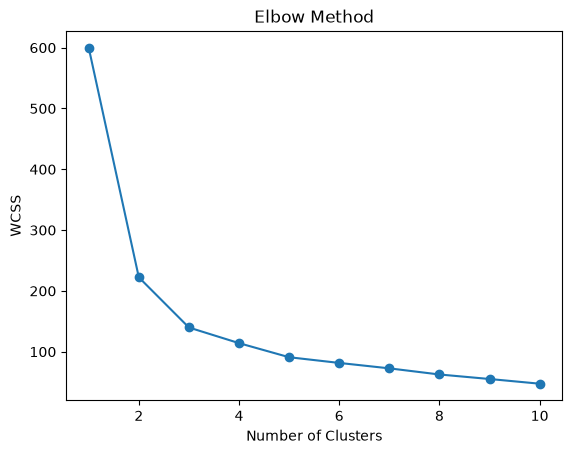

In [4]:
# Elbow Method
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

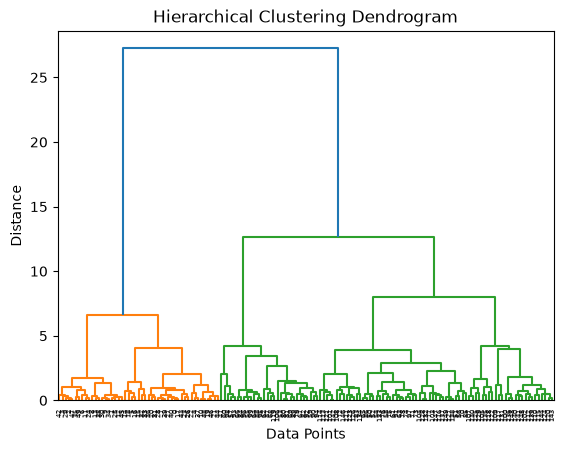

In [5]:
# Dendrogram
Z = linkage(X, method='ward')
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

In [6]:
# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

In [7]:
# Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X)

In [8]:
# Display cluster counts
print("K-Means Cluster Counts:")
print(__import__('numpy').bincount(kmeans_labels))

K-Means Cluster Counts:
[53 50 47]


In [9]:
print("\nHierarchical Cluster Counts:")
print(__import__('numpy').bincount(hierarchical_labels))


Hierarchical Cluster Counts:
[71 49 30]


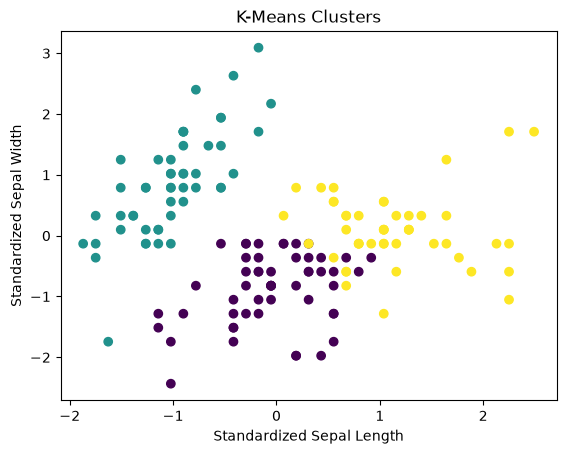

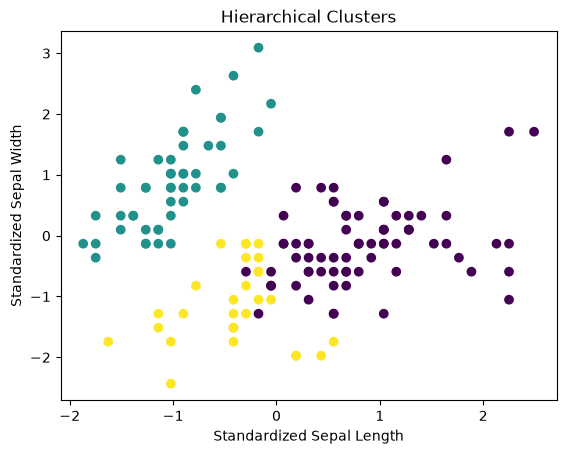

In [10]:
# Visualize clusters using first two features
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels)
plt.title('K-Means Clusters')
plt.xlabel('Standardized Sepal Length')
plt.ylabel('Standardized Sepal Width')
plt.show()

plt.scatter(X[:, 0], X[:, 1], c=hierarchical_labels)
plt.title('Hierarchical Clusters')
plt.xlabel('Standardized Sepal Length')
plt.ylabel('Standardized Sepal Width')
plt.show()